# **01 - Data Ingestion & Validation Pipeline**

## **1. Pipeline Objective**

## **2. Dependency Management**

### **2.1 Package Installation**

In [1]:
!pip install -q datasets pyarrow pandas matplotlib seaborn

### **2.2 Module Imports**

In [2]:
import json
import os
from typing import Tuple, List

import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from huggingface_hub import login

### **2.3 Environment Variables**

In [3]:
RANDOM_SEED: int = 42
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_RAW_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'raw')
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')

DATASET_NAME: str = "davidanugraha/IndoPref"
SPLIT_NAME: str = "test"
EXPECTED_ROWS: int = 4099

print(
    f"[DATASET] name='{DATASET_NAME}' | "
    f"split='{SPLIT_NAME}' | "
    f"expected_rows={EXPECTED_ROWS}"
)

[DATASET] name='davidanugraha/IndoPref' | split='test' | expected_rows=4099


## **3. Resource Allocation**

### **3.1 Identity & Access Management (IAM)**

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')

    secrets_path: str = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token: str = secrets.get("HF_TOKEN", "")
        if hf_token:
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

Mounted at /content/drive
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'


### **3.2 Storage Initialization**

In [5]:
for d in [DATA_RAW_DIR, DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

## **4. Data Ingestion & Bronze Checkpoint**

In [6]:
dataset = load_dataset(DATASET_NAME, split=SPLIT_NAME)
df_indopref: pd.DataFrame = dataset.to_pandas()
assert len(df_indopref) == EXPECTED_ROWS, (
    f"[DATASET] status=FAILED | "
    f"expected={EXPECTED_ROWS} | "
    f"actual={len(df_indopref)}"
)
print(f"[DATASET] rows={len(df_indopref)} | status=VALIDATED")
df_indopref.info()

README.md:   0%|          | 0.00/651 [00:00<?, ?B/s]

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.29MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4099 [00:00<?, ? examples/s]

[DATASET] rows=4099 | status=VALIDATED
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4099 entries, 0 to 4098
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              4099 non-null   int64 
 1   original_id     4099 non-null   int64 
 2   domain          4099 non-null   object
 3   input           4099 non-null   object
 4   response_1      4099 non-null   object
 5   response_2      4099 non-null   object
 6   chosen_model    4099 non-null   object
 7   rejected_model  4099 non-null   object
 8   actual_score    4099 non-null   object
 9   language        4099 non-null   object
dtypes: int64(2), object(8)
memory usage: 320.4+ KB


In [7]:
raw_path: str = os.path.join(DATA_RAW_DIR, 'indopref_raw.parquet')
df_indopref.to_parquet(raw_path, index=False)
print(f"[DATASET] status=SAVED | path='{raw_path}'")

[DATASET] status=SAVED | path='/content/drive/MyDrive/LLMReliability/data/raw/indopref_raw.parquet'


## **5. Schema Validation Engine**

In [8]:
def validate_dataset(df: pd.DataFrame):
    required_cols: List[str] = ['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score']
    
    missing_cols = [c for c in required_cols if c not in df.columns]
    if missing_cols:
        print(f"[VALIDATION] status=FAILED | error='missing_columns' | columns={missing_cols}")
        return False

    null_counts = df[required_cols].isnull().sum()
    if null_counts.sum() > 0:
        print(f"[VALIDATION] status=FAILED | error='null_values' | columns={list(null_counts[null_counts > 0].index)}")
        return False

    for col in ['input', 'response_1', 'response_2']:
        invalid_mask = df[col].astype(str).str.strip().eq("")
        if invalid_mask.any():
            print(f"[VALIDATION] status=FAILED | error='string_anomaly' | column='{col}' | count={invalid_mask.sum()}")
            return False
    
    return True

In [9]:
if not validate_dataset(df_indopref):
    raise ValueError(
        "[VALIDATION] status=FAILED | "
        "error='schema_check' | "
        "action='execution_halted'"
    )

## **6. Deduplication Process**

In [10]:
duplicates_before = df_indopref.duplicated(subset=['original_id']).sum()
print(f"[VALIDATION] duplicates={duplicates_before} | status=DETECTED")

if duplicates_before > 0:
    df_indopref = df_indopref.drop_duplicates(subset=['original_id']).copy()
    print(f"[VALIDATION] rows={len(df_indopref)} | status=DEDUPLICATED")
else:
    print("[VALIDATION] duplicates=0 | status=CLEAN")

EXPECTED_CLEAN_ROWS = len(df_indopref)
assert len(df_indopref) == EXPECTED_CLEAN_ROWS

[VALIDATION] duplicates=3580 | status=DETECTED
[VALIDATION] rows=519 | status=DEDUPLICATED


## **7. Exploratory Data Analysis (EDA)**

### **7.1 Data Structure Profiling**

,domain,input,chosen_model,rejected_model
0,logic,Jika Anda menambah kecepatan kendaraan tiba-ti...,Aya-Expanse-8B,Llama-3.1-8B-Instruct
1,brainstorming,Jika Anda memiliki kesempatan untuk memulai ke...,GPT 4o,GPT 4o mini
2,logic,"Sebuah taman memiliki tiga jenis bunga: mawar,...",Gemini-1.5-Flash,Aya-Expanse-8B


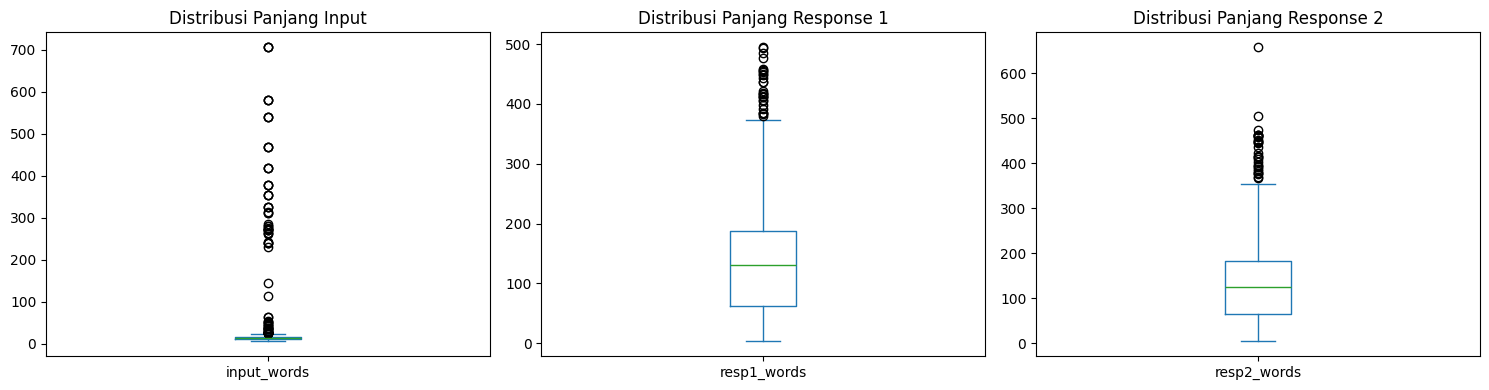

[EDA] max_word_count=706


In [11]:
display(df_indopref[['domain', 'input', 'chosen_model', 'rejected_model']].head(3))

df_eda = df_indopref.copy()
df_eda['input_words'] = df_eda['input'].apply(lambda x: len(str(x).split()))
df_eda['resp1_words'] = df_eda['response_1'].apply(lambda x: len(str(x).split()))
df_eda['resp2_words'] = df_eda['response_2'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df_eda['input_words'].plot(kind='box', ax=axes[0], title='Distribusi Panjang Input')
df_eda['resp1_words'].plot(kind='box', ax=axes[1], title='Distribusi Panjang Response 1')
df_eda['resp2_words'].plot(kind='box', ax=axes[2], title='Distribusi Panjang Response 2')
plt.tight_layout()
plt.show()

max_words = df_eda[['input_words', 'resp1_words', 'resp2_words']].max().max()
print(f"[EDA] max_word_count={max_words}")

### **7.2 Target Variable Distribution**

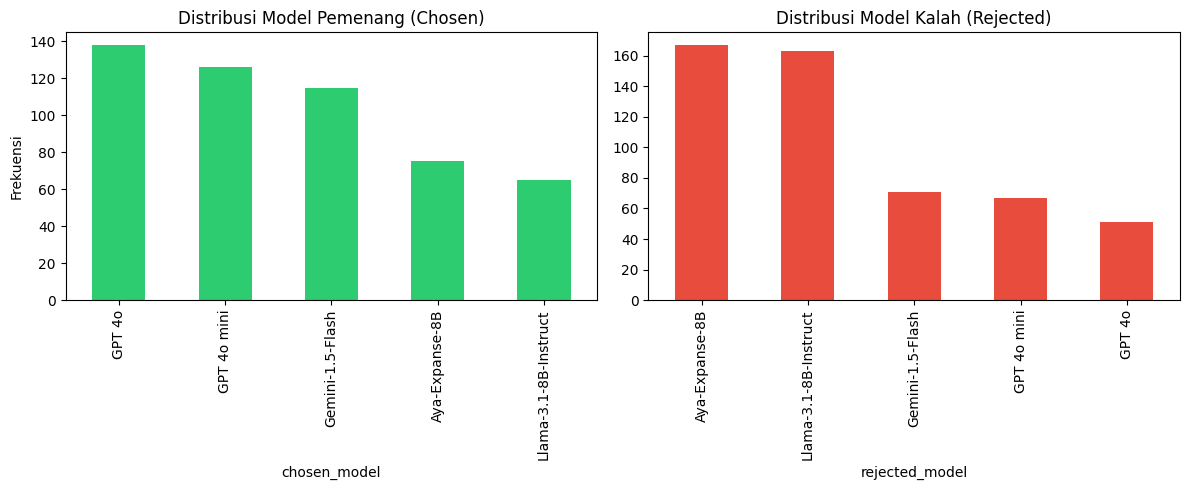

In [12]:
chosen_counts = df_indopref['chosen_model'].value_counts()
rejected_counts = df_indopref['rejected_model'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
chosen_counts.plot(kind='bar', ax=axes[0], color='#2ecc71')
axes[0].set_title('Distribusi Model Pemenang (Chosen)')
axes[0].set_ylabel('Frekuensi')

rejected_counts.plot(kind='bar', ax=axes[1], color='#e74c3c')
axes[1].set_title('Distribusi Model Kalah (Rejected)')

plt.tight_layout()
plt.show()

## **8. Pilot Data Extraction**

In [13]:
df_pilot, df_main = train_test_split(
    df_indopref, train_size=150, stratify=df_indopref['domain'], random_state=RANDOM_SEED
)

print(
    f"[PARTITION] method='train_test_split' | "
    f"pilot={len(df_pilot)} | "
    f"main={len(df_main)} | "
    f"status=COMPLETED"
)

pilot_path: str = os.path.join(DATA_PROCESSED_DIR, 'indopref_pilot.parquet')
main_path: str = os.path.join(DATA_PROCESSED_DIR, 'indopref_main.parquet')
df_pilot.to_parquet(pilot_path, index=False)
df_main.to_parquet(main_path, index=False)

print(f"[OUTPUT] split='pilot' | path='{pilot_path}' | status=SAVED")
print(f"[OUTPUT] split='main' | path='{main_path}' | status=SAVED")

[PARTITION] method='train_test_split' | pilot=150 | main=369 | status=COMPLETED
[OUTPUT] split='pilot' | path='/content/drive/MyDrive/LLMReliability/data/processed/indopref_pilot.parquet' | status=SAVED
[OUTPUT] split='main' | path='/content/drive/MyDrive/LLMReliability/data/processed/indopref_main.parquet' | status=SAVED
